# Project: Telco Customer Churn Prediction

Import All Libraries


In [80]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,cross_val_score, GridSearchCV
from sklearn.preprocessing import OneHotEncoder,LabelEncoder,StandardScaler
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,roc_auc_score,ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline,make_pipeline
from google.colab import drive
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.compose import make_column_transformer,ColumnTransformer
from sklearn.impute import SimpleImputer
import joblib

In [81]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Data Loading & Inspection**

In [82]:
df = pd.read_csv('/content/drive/MyDrive/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [83]:
df.shape

(7043, 21)

In [84]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [85]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [86]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [87]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [88]:
df.duplicated().sum()

np.int64(0)

In [89]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


**Data Cleaning**

In [90]:
print((df['TotalCharges'].str.strip() == '').sum())

11


In [91]:
print((df['TotalCharges'].str.strip() == '').sum())

11


In [92]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'],errors='coerce')

In [93]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [94]:
df['TotalCharges'].dtype

dtype('float64')

In [95]:
print(df[df['TotalCharges'].isna()][['customerID', 'tenure', 'TotalCharges']])

      customerID  tenure  TotalCharges
488   4472-LVYGI       0           NaN
753   3115-CZMZD       0           NaN
936   5709-LVOEQ       0           NaN
1082  4367-NUYAO       0           NaN
1340  1371-DWPAZ       0           NaN
3331  7644-OMVMY       0           NaN
3826  3213-VVOLG       0           NaN
4380  2520-SGTTA       0           NaN
5218  2923-ARZLG       0           NaN
6670  4075-WKNIU       0           NaN
6754  2775-SEFEE       0           NaN


In [96]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [97]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [98]:
df.duplicated().sum()

np.int64(0)

**EDA — Exploratory Data Analysis**

In [99]:
sns.set_theme(style='whitegrid')

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


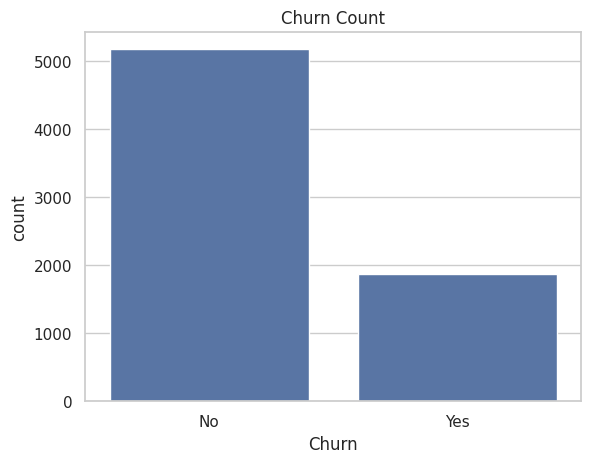

In [100]:
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True) * 100)

sns.countplot(data=df,x='Churn')
plt.title('Churn Count')
plt.show()

About 73.5% of customers stayed (No) and 26.5% churned (Yes). The data is imbalanced, so accuracy alone will be misleading and recall, precision and F1 must also be checked.

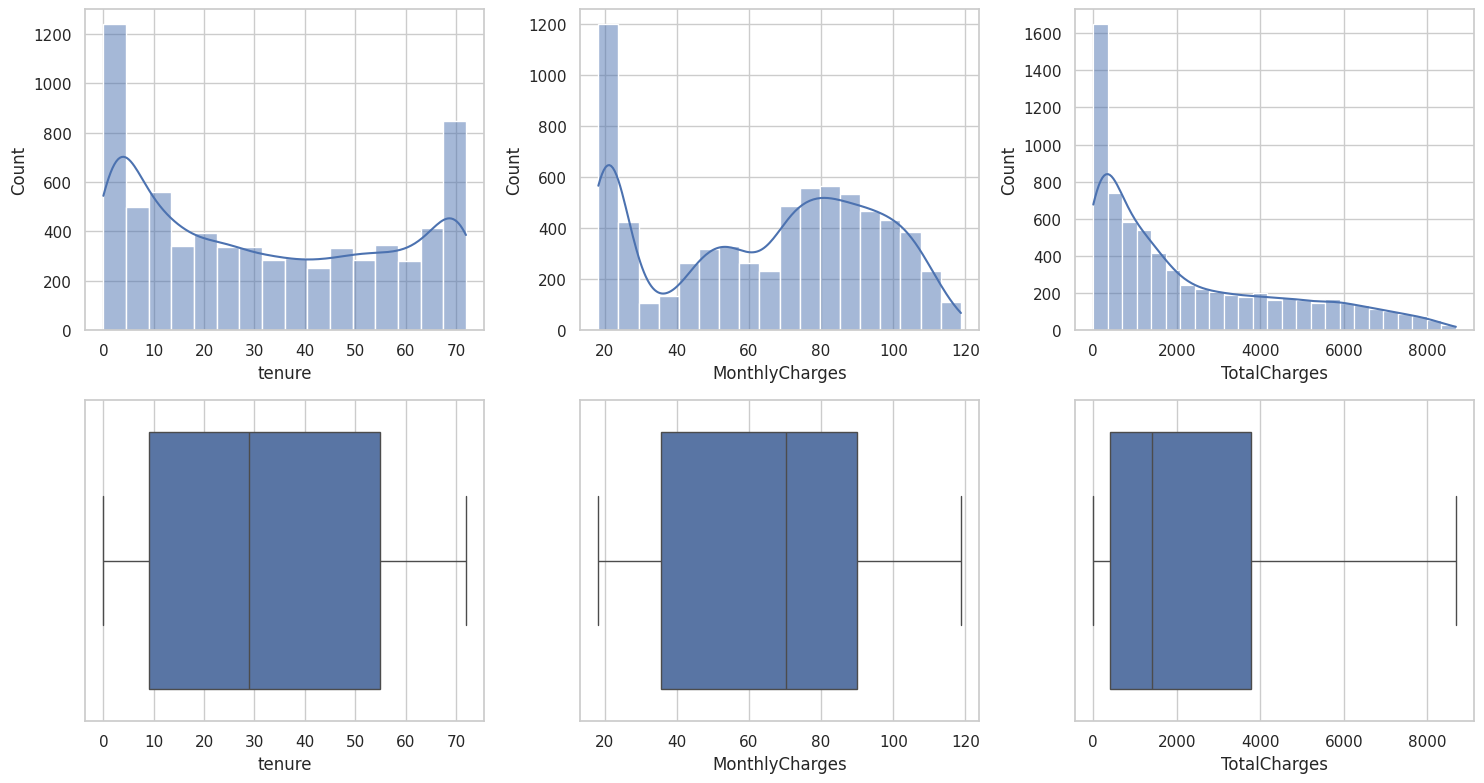

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


In [101]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, kde=True, ax=ax[0, i])
    sns.boxplot(data=df, x=col, ax=ax[1, i])
plt.tight_layout()
plt.show()

df[num_cols].describe()

Tenure has two peaks, one for very new customers (0 to 1 months) and one for long-term customers (around 72 months). TotalCharges is right-skewed because most customers have low cumulative bills. The boxplots show no serious outliers in any of the three columns.

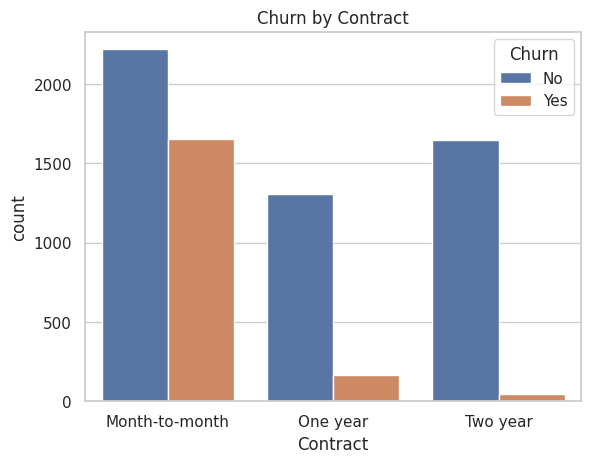

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64


In [102]:
sns.countplot(data=df,x='Contract',hue='Churn')
plt.title('Churn by Contract')
plt.show()

print(df.groupby('Contract')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).round(1))

Month-to-month customers churn at roughly 43%, compared with about 11% for one-year and about 3% for two-year contracts. Customers without a long-term commitment are by far the most likely to leave.

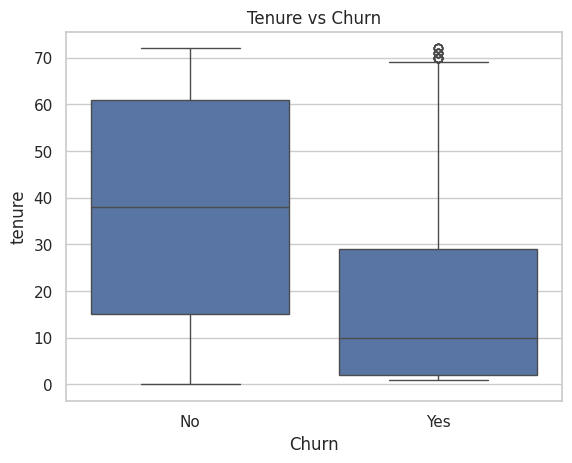

Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64


In [103]:
sns.boxplot(data=df,x='Churn',y='tenure')
plt.title('Tenure vs Churn')
plt.show()

print(df.groupby('Churn')['tenure'].median())

Churned customers have a much lower median tenure (about 10 months) than retained customers (about 38 months). Customers are most likely to leave early in their relationship with the company.

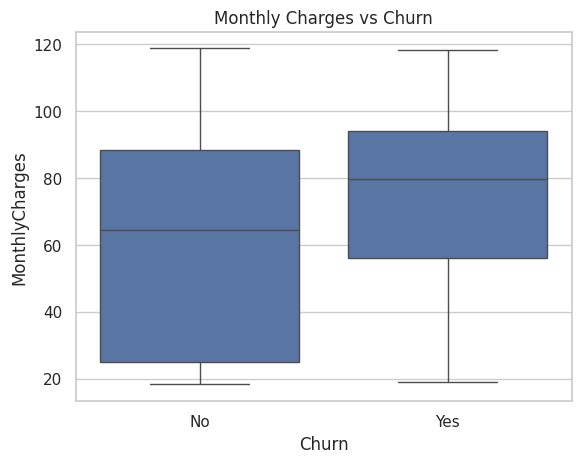

Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64


In [104]:
sns.boxplot(data=df,x='Churn',y='MonthlyCharges')
plt.title('Monthly Charges vs Churn')
plt.show()

print(df.groupby('Churn')['MonthlyCharges'].median())

Churned customers pay higher monthly charges (median about 80) than retained customers (median about 64). Higher bills are associated with higher churn.

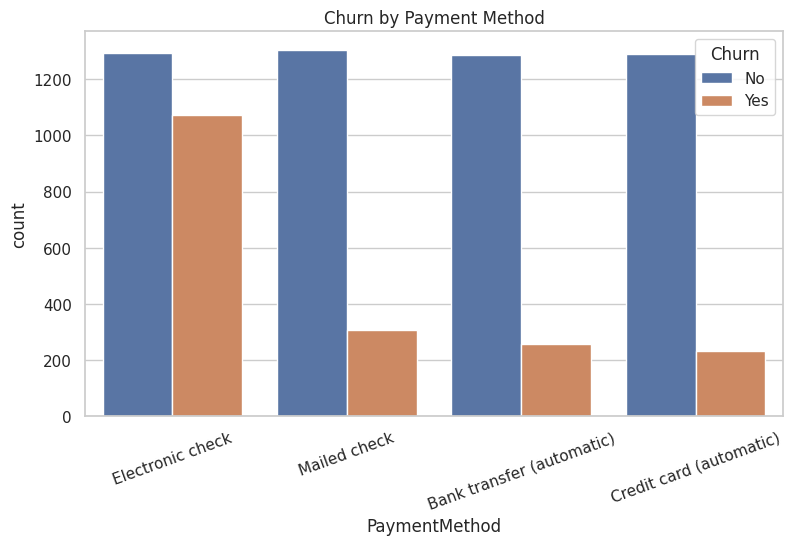

PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1
Name: Churn, dtype: float64


In [105]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x='PaymentMethod', hue='Churn')
plt.xticks(rotation=20)
plt.title('Churn by Payment Method')
plt.show()

print(df.groupby('PaymentMethod')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).round(1))

Electronic check users churn the most (about 45%), while customers on automatic payments (bank transfer or credit card) churn at only about 15 to 17%.

In [106]:
print(df.groupby('InternetService')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).round(1))
print(df.groupby('TechSupport')['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).round(1))

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn, dtype: float64
TechSupport
No                     41.6
No internet service     7.4
Yes                    15.2
Name: Churn, dtype: float64


Fiber optic customers churn more (about 42%) than DSL customers (about 19%). Customers without TechSupport churn at about 42%, versus about 15% for those with it.

**Short Report**

Overall churn:

About 26.5% of customers churned, which means roughly 1 in 4 customers leaves. Even a small improvement in retention would protect a large amount of monthly revenue.

Contract type:

Month-to-month customers churn at about 43%, versus about 3% for two-year contracts. The company should offer discounts or bonus services to move month-to-month customers onto one-year or two-year contracts.

Tenure:

Most churn happens in the first few months of the relationship. The company should run a strong onboarding program and follow-up calls during the first 3 to 6 months to keep new customers engaged.

Monthly charges:

Churned customers pay higher monthly bills than retained ones. The company should review pricing for high-bill customers and offer tailored plans or loyalty discounts before they leave.

Payment method:

Electronic check users churn the most (about 45%), while automatic payment users churn at only about 15 to 17%. The company should encourage customers to switch to automatic bank or credit card payments, for example with a small cashback.

Internet service and tech support:

Fiber optic customers and customers without TechSupport churn more. The company should investigate fiber optic service quality and promote tech support as a free trial or bundled add-on.

Final summary (conclusion):

The highest-risk customers are new, on month-to-month contracts, paying high monthly bills by electronic check, and without tech support. The retention team should target this group first with offers and proactive outreach, since keeping an existing customer costs less than acquiring a new one.

**Target aur features**

In [107]:
from sklearn.model_selection import train_test_split

# 1. Churn ko 1/0 me convert karo
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# 2. Target aur features alag karo
y = df['Churn']
x = df.drop(columns=['customerID', 'Churn'])

# 3. Train/test split
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

In [108]:
print(x_train.shape,x_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())
print('customerID' in x.columns)
print(df['Churn'].unique())

(5634, 19) (1409, 19)
Churn
0    4139
1    1495
Name: count, dtype: int64
Churn
0    1035
1     374
Name: count, dtype: int64
False
[0 1]


**Preprocessing pipeline**

In [110]:
numerical_features = ['tenure','MonthlyCharges','TotalCharges']
categorical_features = [c for c in x.columns if c not in numerical_features]


In [112]:
print(len(numerical_features), len(categorical_features))

3 16


In [113]:
numeric_pipeline_scaled = Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler())
])

numeric_pipeline_tree = Pipeline([
    ('imputer',SimpleImputer(strategy='median'))
])

categorical_pipeline = Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('onehot',OneHotEncoder(handle_unknown='ignore'))
])


In [114]:
preprocessor_scaled = ColumnTransformer([
    ('num',numeric_pipeline_scaled,numerical_features),
    ('cat',categorical_pipeline,categorical_features)
])

preprocessor_tree = ColumnTransformer([
    ('num',numeric_pipeline_tree,numerical_features),
    ('cat',categorical_pipeline,categorical_features)
])

In [115]:
preprocessor_scaled.fit(x_train)
x_train_processed = preprocessor_scaled.transform(x_train)
print(x_train_processed.shape)

(5634, 46)


In [120]:
x_test_processed = preprocessor_scaled.transform(x_test)
print(x_test_processed.shape)

(1409, 46)


**Baseline aur model comparison**

In [123]:
pipelines = {
    'Dummy': Pipeline([
        ('prep',preprocessor_tree),
        ('model',DummyClassifier(strategy='most_frequent'))
    ]),
    'Logistic Regression': Pipeline([
        ('prep',preprocessor_scaled),
        ('model',LogisticRegression(max_iter=1000))
    ]),
    'Decision Tree': Pipeline([
        ('prep',preprocessor_tree),
        ('model',DecisionTreeClassifier(random_state=42))
    ]),
    'Random Forest': Pipeline([
        ('prep',preprocessor_tree),
        ('model',RandomForestClassifier(random_state=42))
    ]),
}

results = []
for name,pipe in pipelines.items():
  pipe.fit(x_train,y_train)
  y_pred = pipe.predict(x_test)
  y_prob = pipe.predict_proba(x_test)[:,1]

  results.append({
      'Model' : name,
      'Accuracy': accuracy_score(y_test,y_pred),
      'Precision': precision_score(y_test,y_pred),
      'Recall': recall_score(y_test,y_pred),
      "F1": f1_score(y_test, y_pred),
      "ROC-AUC": roc_auc_score(y_test, y_prob),
  })

  print(name)
  print(confusion_matrix(y_test, y_pred))
  print()


results_df = pd.DataFrame(results).round(3)
print(results_df)


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Dummy
[[1035    0]
 [ 374    0]]

Logistic Regression
[[926 109]
 [165 209]]

Decision Tree
[[830 205]
 [194 180]]

Random Forest
[[920 115]
 [192 182]]

                 Model  Accuracy  Precision  Recall     F1  ROC-AUC
0                Dummy     0.735      0.000   0.000  0.000    0.500
1  Logistic Regression     0.806      0.657   0.559  0.604    0.842
2        Decision Tree     0.717      0.468   0.481  0.474    0.641
3        Random Forest     0.782      0.613   0.487  0.542    0.819


**Error analysis aur tuning**

In [126]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

for name in ['Logistic Regression','Random Forest']:
  scores = cross_val_score(pipelines[name],x_train,y_train,cv=cv,scoring='roc_auc')
  print(f"{name}: mean={scores.mean():.3f}, std={scores.std():.3f}")

Logistic Regression: mean=0.846, std=0.013
Random Forest: mean=0.818, std=0.011


In [128]:
lr_balanced = Pipeline([
    ('prep',preprocessor_scaled),
    ('model',LogisticRegression(max_iter=1000,class_weight='balanced'))
])

lr_balanced.fit(x_train,y_train)
y_pred_b = lr_balanced.predict(x_test)
y_prob_b = lr_balanced.predict_proba(x_test)[:, 1]

print(confusion_matrix(y_test, y_pred_b))
print("Accuracy:", round(accuracy_score(y_test, y_pred_b), 3))
print("Precision:", round(precision_score(y_test, y_pred_b), 3))
print("Recall:", round(recall_score(y_test, y_pred_b), 3))
print("F1:", round(f1_score(y_test, y_pred_b), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_b), 3))

[[747 288]
 [ 81 293]]
Accuracy: 0.738
Precision: 0.504
Recall: 0.783
F1: 0.614
ROC-AUC: 0.842


In [129]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [None, "balanced"],
}

grid = GridSearchCV(
    pipelines["Logistic Regression"],
    param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)
grid.fit(x_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV F1:", round(grid.best_score_, 3))

Best params: {'model__C': 0.1, 'model__class_weight': 'balanced'}
Best CV F1: 0.629


In [131]:
best_model = grid.best_estimator_

y_pred_final = best_model.predict(x_test)
y_prob_final = best_model.predict_proba(x_test)[:, 1]

print(confusion_matrix(y_test, y_pred_final))
print("Accuracy:", round(accuracy_score(y_test, y_pred_final), 3))
print("Precision:", round(precision_score(y_test, y_pred_final), 3))
print("Recall:", round(recall_score(y_test, y_pred_final), 3))
print("F1:", round(f1_score(y_test, y_pred_final), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_final), 3))

[[751 284]
 [ 80 294]]
Accuracy: 0.742
Precision: 0.509
Recall: 0.786
F1: 0.618
ROC-AUC: 0.841


**Final model aur report**

In [132]:
import joblib

joblib.dump(best_model,'churn_pipeline.joblib')

['churn_pipeline.joblib']

In [133]:
loaded = joblib.load('churn_pipeline.joblib')

In [135]:
print((loaded.predict(x_test) == best_model.predict(x_test)).all())

True


In [137]:
print(loaded.named_steps.keys())

dict_keys(['prep', 'model'])


In [138]:
sample = x_test.iloc[[0]]
print(loaded.predict(sample))
print(loaded.predict_proba(sample))

[0]
[[0.89082444 0.10917556]]


In [143]:
import sklearn, pandas, numpy, joblib
print("pandas==" + pandas.__version__)
print("numpy==" + numpy.__version__)
print("scikit-learn==" + sklearn.__version__)
print("joblib==" + joblib.__version__)

pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
joblib==1.6.0


# **Final Business Report &Insights

# Telco Customer Churn Prediction: Final Report

## 1. Business Problem
A telecom company loses revenue every time a customer cancels service. Acquiring a new customer costs more than retaining an existing one, so the company wants to identify customers who are likely to leave **before** they cancel and act early with retention offers.

**Goal:** Predict whether a customer will churn (Yes/No) and estimate the probability of churn.
**Problem type:** Supervised machine learning, binary classification.

## 2. Dataset
- Telco Customer Churn dataset (Kaggle), 7,043 customers and 21 columns.
- Target: `Churn` (1 = left, 0 = stayed). About 26.5% of customers churned, so the data is imbalanced.
- Features: demographics (gender, SeniorCitizen, Partner, Dependents), account info (tenure, Contract, PaperlessBilling, PaymentMethod), services (PhoneService, InternetService, TechSupport, etc.) and charges (MonthlyCharges, TotalCharges).

## 3. Data Cleaning
- `TotalCharges` was stored as text because of 11 blank values. I converted it to numeric.
- All 11 blank rows had `tenure = 0` (brand-new customers with no bill yet), so I filled them with 0, which is a logical and explainable choice.
- No duplicate rows were found. `customerID` was excluded from modeling features to avoid noise and overfitting.

## 4. Exploratory Data Analysis: Key Insights
| Factor | Finding | Business meaning |
|---|---|---|
| Overall churn | About 26.5% churn (1 in 4 customers) | Retention has a large revenue impact |
| Contract | Month-to-month ~43%, one-year ~11%, two-year ~3% | Customers without commitment leave most |
| Tenure | Churners have a much lower median tenure than retained customers | Most churn happens early in the relationship |
| Monthly charges | Churners pay higher monthly bills | Price-sensitive customers are at risk |
| Payment method | Electronic check ~45% vs automatic payments ~15-17% | Payment method is linked to loyalty |
| Internet service | Fiber optic customers churn more than DSL | Possible service quality or price issue |
| Tech support | Customers without TechSupport churn much more | Support add-ons are linked to retention |

*These are associations, not proof of cause.*

## 5. Modeling Approach
- 80/20 train/test split (`random_state=42`, `stratify=y`).
- A single sklearn Pipeline with ColumnTransformer: median imputation and StandardScaler for numeric features, most-frequent imputation and OneHotEncoder (`handle_unknown='ignore'`) for categorical features. All preprocessing is fitted on training data only, which prevents data leakage.
- Models compared: Dummy baseline, Logistic Regression, Decision Tree, Random Forest. Scaling was applied only for Logistic Regression.

## 6. Model Comparison (default settings, test set)
| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Dummy | 0.735 | 0.000 | 0.000 | 0.000 | 0.500 |
| Logistic Regression | 0.806 | 0.657 | 0.559 | 0.604 | 0.842 |
| Decision Tree | 0.717 | 0.468 | 0.481 | 0.474 | 0.641 |
| Random Forest | 0.782 | 0.613 | 0.487 | 0.542 | 0.819 |

- The Dummy model reaches 73.5% accuracy but catches zero churners, which shows that accuracy alone is misleading on imbalanced data.
- The unrestricted Decision Tree overfits and performs worst.
- Logistic Regression was best on every metric and is also the most interpretable.

## 7. Error Analysis and Tuning
- **Cross-validation:** 5-fold stratified CV was used to check stability (mean ROC-AUC: ___ , std: ___ ; fill from your output).
- **class_weight='balanced':** Recall rose from 0.559 to 0.783 and missed churners fell from 165 to 81. Precision fell from 0.657 to 0.504 and false alarms rose from 109 to 288. ROC-AUC stayed at 0.842, so the model's ranking ability did not change, only the decision threshold.
- **GridSearchCV** (5-fold, scoring = F1) selected C=0.1 and class_weight='balanced', with a cross-validated F1 of 0.629.

## 8. Final Model
**Logistic Regression (C=0.1, class_weight='balanced')**, saved as a full pipeline (`churn_pipeline.joblib`).

| Metric | Test result |
|---|---|
| Accuracy | 0.742 |
| Precision | 0.509 |
| Recall | 0.786 |
| F1 | 0.618 |
| ROC-AUC | 0.841 |

Confusion matrix: TN = 751, FP = 284, FN = 80, TP = 294.
The model catches 294 of 374 churners (78.6%). About half of the customers it flags are false alarms.

The cross-validated F1 (0.629) is close to the test F1 (0.618), which suggests the model is stable and not overfitted. The test set was used once for final evaluation.

## 9. Business Recommendations
1. **Move customers to longer contracts.** Offer discounts or bonus services to month-to-month customers who switch to one- or two-year plans.
2. **Strengthen onboarding.** Run welcome offers and follow-up calls during the first 3-6 months, when churn risk is highest.
3. **Encourage automatic payments.** Offer a small cashback for switching from electronic check to bank transfer or credit card.
4. **Promote tech support.** Bundle TechSupport or offer a free trial, especially to fiber optic customers.
5. **Review pricing and fiber service quality.** High-bill and fiber optic customers churn more and need competitive plans or quality checks.
6. **Use the model for proactive outreach.** Score customers monthly and contact the highest-risk group first with tailored retention offers.

## 10. Limitations
- Based on a single dataset from one company, so results may not transfer to other markets.
- Precision is about 51%, meaning roughly half of the alerts are false alarms. The model suits cases where a retention offer is cheaper than losing a customer.
- Predicted probabilities are estimates, not guarantees.
- The data is a snapshot. It has no information on customer complaints, network quality or competitor offers.
- Findings are associations, not proven causes.

## 11. Next Steps
- Deploy the saved pipeline in a Streamlit app that shows churn probability for a new customer.
- Try Gradient Boosting and threshold tuning.
- Estimate the real cost of a lost customer versus a retention offer to choose the best decision threshold.

**